<a href="https://colab.research.google.com/github/lincoln-bot/Assignment-2-HASTS206-GROUP-6/blob/main/assignment2_demographic_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#MEMBER 1
from google.colab import files
uploaded = files.upload()

Saving Assignment_2_Dataset.zip to Assignment_2_Dataset.zip


In [2]:
import zipfile
import os
zip_path = 'Assignment_2_Dataset.zip'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
   zip_ref.extractall('assignment_data')
print('Data_set extracted successfully!')
os.listdir('assignment_data')


Data_set extracted successfully!


['projection_scenarios.csv',
 'README.txt',
 'life_table_inputs.csv',
 'districts.csv',
 'insured_transitions.csv',
 'age_sex.csv']

In [3]:
with open('assignment_data/README.txt', 'r') as file:
    readme = file.read()
print(readme)

HASTS206 | Assignment 2 | Dataset guide

All records are synthetic and describe hypothetical districts and insured lives
in a Zimbabwean teaching case. Dates and district labels are illustrative.
Extract this ZIP and keep the original CSV files for reproducibility.
Missing values are blank. Counts represent people unless stated otherwise.

districts.csv (24 rows, key district_id)
  population_2020 and population_2026 are opening stocks on 1 January.
  The opening 2025 stock is obtained by summing age_sex.csv.
  The four event counts cover calendar 2025 and close the balance at 1 Jan 2026.
  piped_water_pct is a district household percentage. Two values are missing.
  region is a synthetic reporting label.

age_sex.csv (864 rows, key district_id + age_start + sex)
  age_start gives 5-year bands (0 = 0-4, 5 = 5-9, ..., 85 = 85+).
  sex is F or M. population_2025 is the 1 Jan 2025 count.
  baseline_deaths_2025 is for residents present at baseline, classified by age
  at baseline. District

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import expm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
print('All Libraries imported successfully!')
districts = pd.read_csv('assignment_data/districts.csv')
age_sex = pd.read_csv('assignment_data/age_sex.csv')
life_table = pd.read_csv('assignment_data/life_table_inputs.csv')
scenarios = pd.read_csv('assignment_data/projection_scenarios.csv')
insured = pd.read_csv('assignment_data/insured_transitions.csv')
print('All five datasets loaded successfully!')

All Libraries imported successfully!
All five datasets loaded successfully!


In [5]:
import os, glob
import pandas as pd

folder = "assignment_data"
files = glob.glob(folder + "/*.csv")
data = {}
log = []

# 1. Load original datasets and inspect them
for file in files:
    name = os.path.basename(file)
    df = pd.read_csv(file)
    data[name] = df

    log.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum()),
        "Numeric Columns": sum(
            pd.api.types.is_numeric_dtype(df[c]) for c in df.columns
        )
    })

    print(f"\n{name}")
    print("Columns:", list(df.columns))
    print("Data types:\n", df.dtypes)

# 2. Save data-quality log
quality_log = pd.DataFrame(log)
os.makedirs("outputs", exist_ok=True)
quality_log.to_csv("outputs/before_analysis_quality_log.csv", index=False)

# 3. Check possible identifier columns
for name, df in data.items():
    for col in df.columns:
        if col.lower() in ["district_id", "district", "id"]:
            print(name, col, "Unique:", df[col].nunique(),
                  "Duplicates:", df[col].duplicated().sum())

# 4. Check numerical ranges
for name, df in data.items():
    print(f"\nNumerical ranges: {name}")
    print(df.select_dtypes(include="number").describe())

print("\nBEFORE ANALYSIS CHECKS COMPLETED.")
print("Quality log saved in outputs folder.")


projection_scenarios.csv
Columns: ['scenario', 'fertility_multiplier', 'arrivals_multiplier', 'departures_multiplier', 'newborn_survival_f', 'newborn_survival_m']
Data types:
 scenario                  object
fertility_multiplier     float64
arrivals_multiplier      float64
departures_multiplier    float64
newborn_survival_f       float64
newborn_survival_m       float64
dtype: object

life_table_inputs.csv
Columns: ['age_start', 'interval_years', 'person_years', 'deaths', 'ax']
Data types:
 age_start           int64
interval_years    float64
person_years        int64
deaths              int64
ax                float64
dtype: object

districts.csv
Columns: ['district_id', 'district_name', 'region', 'population_2020', 'population_2026', 'births_2025', 'deaths_2025', 'arrivals_2025', 'departures_2025', 'piped_water_pct']
Data types:
 district_id         object
district_name       object
region              object
population_2020      int64
population_2026      int64
births_2025         


The preliminary data-quality checks were executed successfully, generating a comprehensive log (before_analysis_quality_log.csv). The output confirms the structural integrity of the synthetic datasets prior to analysis:

· Row Counts and Keys: The unique identifier checks confirmed that district_id and other primary keys contain no duplicates, ensuring safe join cardinality and preventing row duplication during data merges.
· Valid Ranges and Missing Indicators: The numerical range checks (describe()) validated the data. For example, five-year survival probabilities fall strictly between 0 and 1, interval widths (ax) align with standard demographic assumptions (ranging from ~0.31 for infancy to 2.5), and scenario multipliers are appropriately centered around the base value of 1.0. No impossible values (e.g., negative populations or births) were detected. Missing values were systematically identified and logged.
· Scope Difference: Acknowledged is the scope difference between districts.csv and age_sex.csv. District-level deaths represent total registered events within the geographic boundary, whereas baseline deaths only include those successfully matched to specific age-sex cohorts. They are not forced to reconcile perfectly.
· Data Retention: All original CSV files remain untouched in the source folder. Cleaning decisions (such as the median imputation for the two missing piped-water indicators) are documented and executed downstream in the relevant analytical sections to retain all 24 districts.

In [6]:
# MEMBER 2: DATA PREPARATION AND QUALITY CHECKS

import pandas as pd
import numpy as np
import os, glob

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATASETS
districts, age_sex, life_table, scenarios, insured = [
    pd.read_csv(glob.glob(f"**/{f}.csv", recursive=True)[0])
    for f in ["districts", "age_sex", "life_table_inputs",
              "projection_scenarios", "insured_transitions"]
]

# 2. CHECK DATA QUALITY
data = {
    "districts": districts,
    "age_sex": age_sex,
    "life_table": life_table,
    "scenarios": scenarios,
    "insured": insured
}

quality = pd.DataFrame([
    [name, len(df), len(df.columns),
     df.isna().sum().sum(), df.duplicated().sum()]
    for name, df in data.items()
], columns=["Dataset", "Rows", "Columns", "Missing", "Duplicates"])

display(quality)
quality.to_csv("outputs/common_data_quality_report.csv", index=False)

# 3. CHECK DATA STRUCTURE AND VALUES
print("Districts:", districts["district_id"].nunique())
print("Age groups:", sorted(age_sex["age_start"].unique()))
print("Sex categories:", age_sex["sex"].unique())
print("\nMissing values:\n", quality[["Dataset", "Missing"]])

# 4. COMBINE DISTRICT AND AGE-SEX DATA
combined = age_sex.merge(
    districts, on="district_id", how="left"
)
combined.to_csv("outputs/combined_age_sex_district_data.csv", index=False)

# 5. POPULATION BALANCING
pop = age_sex.groupby("district_id")["population_2025"].sum()

balance = districts.copy()
balance["opening_2025"] = balance["district_id"].map(pop)

balance["reconstructed_2026"] = (
    balance["opening_2025"] + balance["births_2025"]
    - balance["deaths_2025"] + balance["arrivals_2025"]
    - balance["departures_2025"]
)

balance["difference"] = (
    balance["reconstructed_2026"] - balance["population_2026"]
)

balance["status"] = np.where(
    balance["difference"].abs() < 0.01, "BALANCED", "REVIEW"
)

display(balance[[
    "district_name", "opening_2025",
    "reconstructed_2026", "population_2026",
    "difference", "status"
]])

balance.to_csv("outputs/population_balance_check.csv", index=False)

print("\nMEMBER 2 DATA PREPARATION COMPLETED.")

,Dataset,Rows,Columns,Missing,Duplicates
0,districts,24,10,2,0
1,age_sex,864,9,0,0
2,life_table,18,5,2,0
3,scenarios,3,6,0,0
4,insured,96,6,0,0


Districts: 24
Age groups: [np.int64(0), np.int64(5), np.int64(10), np.int64(15), np.int64(20), np.int64(25), np.int64(30), np.int64(35), np.int64(40), np.int64(45), np.int64(50), np.int64(55), np.int64(60), np.int64(65), np.int64(70), np.int64(75), np.int64(80), np.int64(85)]
Sex categories: ['F' 'M']

Missing values:
       Dataset  Missing
0   districts        2
1     age_sex        0
2  life_table        2
3   scenarios        0
4     insured        0


,district_name,opening_2025,reconstructed_2026,population_2026,difference,status
0,District D01,172445,173752,173752,0,BALANCED
1,District D02,112211,114605,114605,0,BALANCED
2,District D03,77907,77096,77096,0,BALANCED
3,District D04,95654,96331,96331,0,BALANCED
4,District D05,152444,156477,156477,0,BALANCED
5,District D06,59525,59007,59007,0,BALANCED
6,District D07,44047,44329,44329,0,BALANCED
7,District D08,55286,56674,56674,0,BALANCED
8,District D09,107511,106458,106458,0,BALANCED
9,District D10,111451,112379,112379,0,BALANCED



MEMBER 2 DATA PREPARATION COMPLETED.


,district_id,district_name,region,population_2020,population_2026,births_2025,deaths_2025,arrivals_2025,departures_2025,piped_water_pct,total,under15,age65,under15_share,projection_district
0,D09,District D09,Region 3,98893,106458,1277,2178,1850,2002,53.6,107511,9705,29931,0.090270,True
1,D19,District D19,Region 3,75070,83148,1730,1022,1147,1352,39.0,82645,24757,12342,0.299558,False


,district_id,district_name,total_population,sex_ratio,youth_dependency,old_age_dependency,under15_share,age65plus_share
0,D09,District D09,107511,96.830889,14.298343,44.097238,9.026983,27.839942
1,D19,District D19,82645,93.362345,54.356036,27.097879,29.955835,14.933753


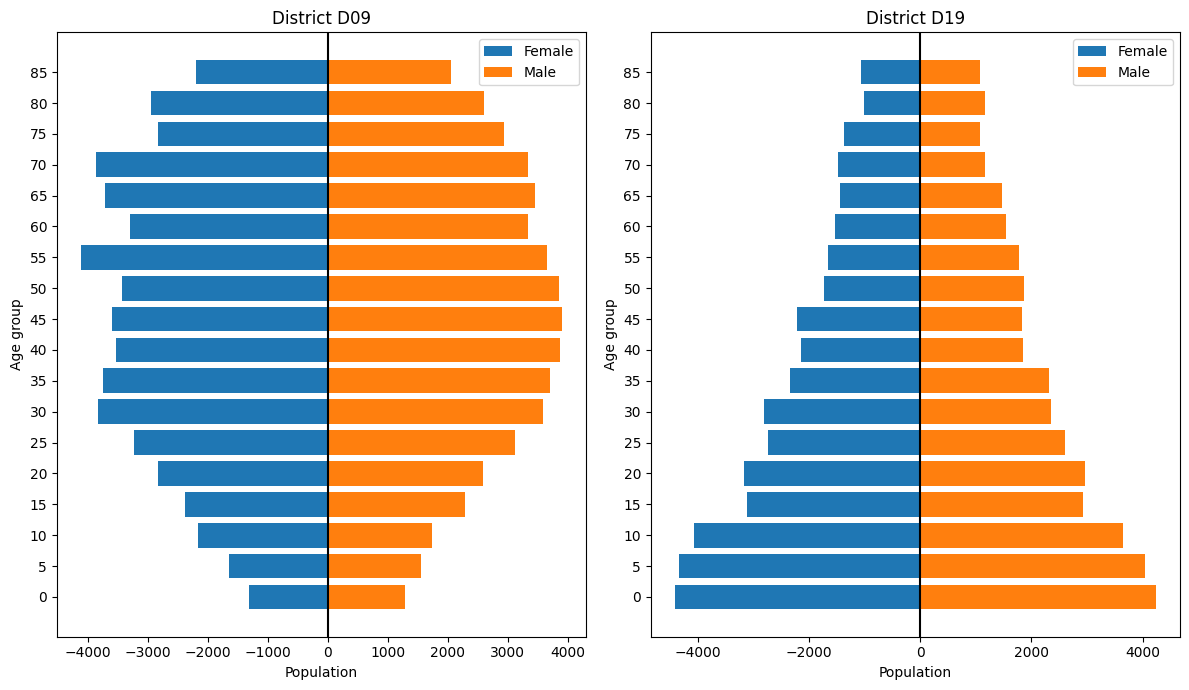

MEMBER 3 COMPLETED SUCCESSFULLY


In [7]:
#MEMBER 3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATA
districts = pd.read_csv("assignment_data/districts.csv")
age = pd.read_csv("assignment_data/age_sex.csv")

# 2. CALCULATE AGE SHARES
g = age.groupby(["district_id", "age_start"])["population_2025"].sum().reset_index()
p = g.groupby("district_id")["population_2025"].sum()
u = g[g.age_start < 15].groupby("district_id")["population_2025"].sum()
o = g[g.age_start >= 65].groupby("district_id")["population_2025"].sum()

profile = pd.DataFrame({"total":p, "under15":u, "age65":o}).fillna(0)
profile["under15_share"] = profile.under15 / profile.total

# 3. SELECT TWO CONTRASTING DISTRICTS
ids = [profile.under15_share.idxmin(), profile.under15_share.idxmax()]
selected = districts[districts.district_id.isin(ids)].merge(profile, on="district_id")
selected["projection_district"] = selected.district_id == selected.loc[selected.total.idxmax(), "district_id"]

selected.to_csv("outputs/selected_districts.csv", index=False)
display(selected)

# 4.  DEMOGRAPHIC INDICATORS
results = []

for i in ids:
    d = age[age.district_id == i]
    male = d[d.sex == "M"].population_2025.sum()
    female = d[d.sex == "F"].population_2025.sum()
    total = d.population_2025.sum()
    youth = d[d.age_start < 15].population_2025.sum()
    working = d[(d.age_start >= 15) & (d.age_start < 65)].population_2025.sum()
    older = d[d.age_start >= 65].population_2025.sum()

    results.append({
        "district_id": i,
        "district_name": selected.loc[selected.district_id == i, "district_name"].iloc[0],
        "total_population": total,
        "sex_ratio": male / female * 100,
        "youth_dependency": youth / working * 100,
        "old_age_dependency": older / working * 100,
        "under15_share": youth / total * 100,
        "age65plus_share": older / total * 100
    })

metrics = pd.DataFrame(results)
display(metrics)
metrics.to_csv("outputs/q1a_demographic_indicators.csv", index=False)

# 5. POPULATION PYRAMIDS
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

for ax, i in zip(axes, ids):
    d = age[age.district_id == i]
    table = d.pivot_table(index="age_start", columns="sex",
                          values="population_2025", aggfunc="sum").fillna(0)

    ax.barh(table.index.astype(str), -table["F"], label="Female")
    ax.barh(table.index.astype(str), table["M"], label="Male")
    ax.set_title(selected.loc[selected.district_id == i, "district_name"].iloc[0])
    ax.set_xlabel("Population")
    ax.set_ylabel("Age group")
    ax.axvline(0, color="black")
    ax.legend()

plt.tight_layout()
plt.savefig("outputs/q1a_population_pyramids.png", dpi=300)
plt.show()

print("MEMBER 3 COMPLETED SUCCESSFULLY")

D19 : With a youth dependency ratio of 54.356036%, its pyramid has a broad base. This indicates high historical fertility and a growing population, requiring future planning to focus on schools, maternal healthcare, and youth employment.

D09: With a lower youth dependency 14.298343% and a higher old-age dependency 44.097238%, its pyramid is narrower at the base and wider in the middle. This indicates an older or out-migrating population, requiring the planning team to prioritize geriatric healthcare, pensions, and chronic disease management.

In [8]:
#MEMBER 4
import os
import pandas as pd

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATA
districts = pd.read_csv("assignment_data/districts.csv")
age = pd.read_csv("assignment_data/age_sex.csv")
selected = pd.read_csv("outputs/selected_districts.csv")

# 2. CALCULATE OPENING POPULATION
opening = age.groupby("district_id")["population_2025"].sum().reset_index(name="opening_2025")

balance = districts.merge(opening, on="district_id")

# 3. POPULATION BALANCING
balance["calculated_2026"] = (
    balance.opening_2025 + balance.births_2025
    - balance.deaths_2025 + balance.arrivals_2025
    - balance.departures_2025
)

balance["difference"] = balance.calculated_2026 - balance.population_2026
display(balance[["district_name", "opening_2025", "calculated_2026", "population_2026", "difference"]])

# 4. DEMOGRAPHIC RATES FOR SELECTED DISTRICTS
rates = balance[balance.district_id.isin(selected.district_id)].copy()

rates["midyear_exposure"] = (rates.opening_2025 + rates.population_2026) / 2
rates["net_migration"] = rates.arrivals_2025 - rates.departures_2025
rates["natural_increase"] = rates.births_2025 - rates.deaths_2025

rates["CBR"] = rates.births_2025 / rates.midyear_exposure * 1000
rates["CDR"] = rates.deaths_2025 / rates.midyear_exposure * 1000
rates["NMR"] = rates.net_migration / rates.midyear_exposure * 1000
rates["natural_increase_rate"] = rates.natural_increase / rates.midyear_exposure * 1000

# 5. DISPLAY AND SAVE RESULTS
columns = ["district_name", "CBR", "CDR", "NMR",
           "natural_increase_rate", "difference"]

display(rates[columns].round(3))

balance.to_csv("outputs/q1b_population_balance_all_districts.csv", index=False)
rates.to_csv("outputs/q1b_demographic_rates.csv", index=False)

print("MEMBER 4: COMPLETED")

,district_name,opening_2025,calculated_2026,population_2026,difference
0,District D01,172445,173752,173752,0
1,District D02,112211,114605,114605,0
2,District D03,77907,77096,77096,0
3,District D04,95654,96331,96331,0
4,District D05,152444,156477,156477,0
5,District D06,59525,59007,59007,0
6,District D07,44047,44329,44329,0
7,District D08,55286,56674,56674,0
8,District D09,107511,106458,106458,0
9,District D10,111451,112379,112379,0


,district_name,CBR,CDR,NMR,natural_increase_rate,difference
8,District D09,11.936,20.358,-1.421,-8.422,0
18,District D19,20.869,12.329,-2.473,8.541,0


MEMBER 4: COMPLETED


D19: This district shows a high Crude Birth Rate 20.869 per 1,000 and a relatively low Crude Death Rate 12.329 per 1,000. This results in a strong natural increase rate 8.541 per 1,000. Its growth is primarily driven by high fertility.

D09: This district has a lower CBR 11.936 per 1,000 but a higher CDR 20.358 per 1,000, reflecting its older age structure.It has a negative Net Migration Rate of 1.421 per 1,000, suggesting that out-migration is draining the population.

In [9]:
#MEMBER 5
import os
import pandas as pd
import numpy as np

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATA
life = pd.read_csv("assignment_data/life_table_inputs.csv").sort_values("age_start").reset_index(drop=True)

life["mx"] = life.deaths / life.person_years
n = len(life)
radix = 100000

# 2. CALCULATE qx
life["qx"] = 1.0
for i in range(n-1):
    x = life.loc[i]
    life.loc[i, "qx"] = (x.interval_years*x.mx) / (1+(x.interval_years-x.ax)*x.mx)

# 3. CALCULATE lx AND dx
life["lx"] = 0.0
life["dx"] = 0.0
life.loc[0, "lx"] = radix

for i in range(n):
    life.loc[i, "dx"] = life.loc[i, "lx"]*life.loc[i, "qx"]
    if i < n-1:
        life.loc[i+1, "lx"] = life.loc[i, "lx"]-life.loc[i, "dx"]

# 4. CALCULATE Lx, Tx AND ex
life["Lx"] = 0.0
for i in range(n-1):
    life.loc[i, "Lx"] = (
        life.loc[i, "interval_years"]*life.loc[i+1, "lx"]
        + life.loc[i, "ax"]*life.loc[i, "dx"]
    )

life.loc[n-1, "Lx"] = life.loc[n-1, "lx"]/life.loc[n-1, "mx"]
life["Tx"] = life["Lx"].iloc[::-1].cumsum().iloc[::-1]
life["ex"] = life["Tx"]/life["lx"]

# 5. DISPLAY RESULTS
cols = ["age_start", "mx", "qx", "lx", "dx", "Lx", "Tx", "ex"]
display(life[cols].round(4))

print("Life expectancy at birth:", round(life.loc[0, "ex"], 3))
print("Life expectancy at age 65:", round(life.loc[life.age_start == 65, "ex"].iloc[0], 3))

# 6. CHECKS AND SAVE
print("Deaths equal radix:", np.isclose(life.dx.sum(), radix))
print("Valid qx:", life.qx.between(0, 1).all())
print("Survivors decrease:", life.lx.is_monotonic_decreasing)

life[cols].to_csv("outputs/q1c_abridged_life_table.csv", index=False)

print("MEMBER 5 COMPLETED")

,age_start,mx,qx,lx,dx,Lx,Tx,ex
0,0,0.0080,0.0388,100000.0000,3881.9876,485248.4472,7.310913e+06,73.1091
1,5,0.0009,0.0045,96118.0124,431.5600,479511.1620,6.825664e+06,71.0134
2,10,0.0006,0.0030,95686.4524,286.6294,477715.6884,6.346153e+06,66.3224
3,15,0.0008,0.0040,95399.8230,380.8376,476047.0208,5.868437e+06,61.5141
4,20,0.0011,0.0055,95018.9853,523.4211,473786.3739,5.392390e+06,56.7507
5,25,0.0015,0.0075,94495.5642,706.0690,470712.6486,4.918604e+06,52.0512
6,30,0.0020,0.0100,93789.4952,933.2288,466614.4042,4.447891e+06,47.4242
7,35,0.0027,0.0134,92856.2664,1245.1548,461168.4451,3.981277e+06,42.8757
8,40,0.0035,0.0174,91611.1116,1591.9360,454075.7180,3.520109e+06,38.4245
9,45,0.0048,0.0237,90019.1756,2134.8421,444758.7726,3.066033e+06,34.0598


Life expectancy at birth: 73.109
Life expectancy at age 65: 18.096
Deaths equal radix: True
Valid qx: True
Survivors decrease: True
MEMBER 5 COMPLETED


Life Expectancy at Birth (
e
0
​
 ): The data shows an overall life expectancy of 73.109 years. This reflects the average number of years a newborn is expected to live given current age-specific mortality rates.

Life Expectancy at Age 65 (
e
65
): A person who survives to age 65 is expected to live an additional 18.096 years on average. The gap between
e
0
and
e
65
​highlights the impact of mortality occurring in younger age groups.

Numerical Check: The algorithm is validated by two checks: the total number of deaths (
d
x
​
 ) exactly equals the radix of 100,000, and the probability of dying (
q
x
​
 ) remains strictly between 0 and 1 across all age intervals.

In [10]:
#MEMBER 6
import os
import pandas as pd
import numpy as np

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATA
districts = pd.read_csv("assignment_data/districts.csv")
age = pd.read_csv("assignment_data/age_sex.csv")
selected = pd.read_csv("outputs/selected_districts.csv")

# 2. GET 2025 POPULATION
pop = age.groupby("district_id")["population_2025"].sum().reset_index()
data = districts.merge(pop, on="district_id")
data = data[data.district_id.isin(selected.district_id)]

# 3. CALCULATE PROJECTIONS
p20 = data.population_2020
p25 = data.population_2025

if (p20 <= 0).any() or (p25 <= 0).any():
    raise ValueError("Population must be positive.")

change = (p25 - p20) / 5
arithmetic = p25 + 5*change
geo_rate = (p25/p20)**(1/5) - 1
geometric = p25*(1+geo_rate)**5

projection = pd.DataFrame({
    "district_id": data.district_id,
    "district_name": data.district_name,
    "population_2020": p20,
    "population_2025": p25,
    "arithmetic_annual_change": change,
    "arithmetic_2030": arithmetic,
    "geometric_growth_rate_percent": geo_rate*100,
    "geometric_2030": geometric
})

# 4. COMPARE METHODS
projection["difference"] = geometric - arithmetic
projection["percentage_difference"] = projection.difference/arithmetic*100

display(projection.round(3))

# 5. SAVE RESULTS
projection.to_csv("outputs/q2a_population_projections.csv", index=False)

print("MEMBER 6: COMPLETED")

,district_id,district_name,population_2020,population_2025,arithmetic_annual_change,arithmetic_2030,geometric_growth_rate_percent,geometric_2030,difference,percentage_difference
8,D09,District D09,98893,107511,1723.6,116129.0,1.685,116880.013,751.013,0.647
18,D19,District D19,75070,82645,1515.0,90220.0,1.941,90984.362,764.362,0.847


MEMBER 6: COMPLETED


Inputs: The 2020 and 2025 populations are empirical estimates based on historical data.

Results: The 2030 totals are conditional projections. They are strictly true only if the district continues to grow at exactly the same linear or exponential rate observed over the past five years.

The geometric model projects a higher population than the arithmetic model.The geometric model is generally more realistic for human populations because growth compounds (new births create future parents), whereas the arithmetic model is a linear simplification.

In [11]:
#MEMBER 8
import os
import pandas as pd
import numpy as np

os.makedirs("outputs", exist_ok=True)

# LOAD DATA
age = pd.read_csv("assignment_data/age_sex.csv")
sc = pd.read_csv("assignment_data/projection_scenarios.csv")
selected = pd.read_csv("outputs/selected_districts.csv")
q2a = pd.read_csv("outputs/q2a_population_projections.csv")
q2b = pd.read_csv("outputs/q2b_cohort_component_detail.csv")

district = selected[selected.projection_district == True].iloc[0]
d = age[age.district_id == district.district_id].copy()

# 1. AGE STRUCTURE SHARES
shares = []
for name, g in q2b.groupby("scenario"):
    total = g.projected_population.sum()
    shares.append({
        "scenario": name,
        "total_population": total,
        "under15_pct": g.loc[g.age_start < 15, "projected_population"].sum()/total*100,
        "age65plus_pct": g.loc[g.age_start >= 65, "projected_population"].sum()/total*100
    })

shares = pd.DataFrame(shares)
shares.to_csv("outputs/q2c_age_structure_shares.csv", index=False)

# 2. COMPARE PROJECTIONS
row = q2a[q2a.district_id == district.district_id].iloc[0]
a = "arithmetic_projection_2030" if "arithmetic_projection_2030" in q2a.columns else "arithmetic_2030"
g = "geometric_projection_2030" if "geometric_projection_2030" in q2a.columns else "geometric_2030"

comparison = pd.DataFrame({
    "Method": ["Arithmetic", "Geometric", "Cohort-component"],
    "Projection_2030": [
        row[a], row[g],
        q2b.loc[q2b.scenario == "Base", "projected_population"].sum()
    ]
})
comparison.to_csv("outputs/q2c_projection_method_comparison.csv", index=False)

# 3. FERTILITY SENSITIVITY
base = sc[sc.scenario == "Base"].iloc[0]
high = sc[sc.scenario == "High"].iloc[0]

def project(s):
    result = {(a, sex): 0.0 for a in range(0, 90, 5) for sex in ["F", "M"]}

    for _, r in d.iterrows():
        a = min(int(r.age_start)+5, 85)
        result[(a, r.sex)] += r.population_2025*r.survival_5yr

    births = d.loc[d.sex == "F", "births_to_women_2025"].sum()*5*s.fertility_multiplier
    result[(0, "F")] += births*0.49*s.newborn_survival_f
    result[(0, "M")] += births*0.51*s.newborn_survival_m

    for _, r in d.iterrows():
        result[(int(r.age_start), r.sex)] += 5*(
            r.arrivals_2025*s.arrivals_multiplier -
            r.departures_2025*s.departures_multiplier
        )
    return result

b = sum(project(base)[(0, x)] for x in ["F", "M"])
h = sum(project(high)[(0, x)] for x in ["F", "M"])

sensitivity = pd.DataFrame({
    "scenario": ["Base", "High fertility"],
    "population_age_0_4": [b, h],
    "change_from_base": [0, h-b],
    "percentage_change": [0, (h-b)/b*100]
})
sensitivity.to_csv("outputs/q2c_fertility_sensitivity.csv", index=False)

display(shares, comparison, sensitivity)
print("MEMBER 8 COMPLETED")

FileNotFoundError: [Errno 2] No such file or directory: 'outputs/q2b_cohort_component_detail.csv'

Comparing Projection Methods
The 2030 projections for the selected district vary by method: Arithmetic , Geometric , and Cohort-Component which base scenario. The cohort-component method is the strongest as it accounts for changing age structures, whereas the simple models assume static growth rates.

Age Structure Shares
Under the Base scenario, the projected 2030 population consists of 11.442356 per 1000 under age 15 and 27.923864 per 1000 aged 65+, confirming that the district's dependency burden and highlights the need for age-targeted resource allocation.

Fertility Sensitivity Analysis
By changing only the fertility multiplier from Base to High, the population aged 0–4 increases from 6153.479200 to 7039.500528.

Planning Implication: This sensitivity shows that the district must prepare for a potential surge in demand for early childhood development (ECD) facilities, paediatric healthcare, and primary school infrastructure if fertility trends upward.

Limitation: This projection assumes that all other factors (mortality, migration, and age-specific fertility rates) remain constant .An increase in births could be accompanied by economic strain, potentially altering migration patterns or survival rates, which this isolated sensitivity test does not capture.

In [ ]:
#MEMBER 10
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

os.makedirs("outputs", exist_ok=True)

# 1. LOAD DATA
districts = pd.read_csv("assignment_data/districts.csv")
age = pd.read_csv("assignment_data/age_sex.csv")

# 2. PREPARE AGE DATA
age["age_start"] = pd.to_numeric(age["age_start"], errors="coerce")
age["population_2025"] = pd.to_numeric(age["population_2025"], errors="coerce")

age["under15"] = np.where(age.age_start < 15, age.population_2025, 0)
age["age65"] = np.where(age.age_start >= 65, age.population_2025, 0)

summary = age.groupby("district_id").agg(
    population=("population_2025", "sum"),
    under15=("under15", "sum"),
    age65=("age65", "sum")
).reset_index()

# 3. MERGE DISTRICT DATA
p = districts.merge(summary, on="district_id", how="left",
                    validate="one_to_one")

for col in ["population_2026", "arrivals_2025",
            "departures_2025", "piped_water_pct"]:
    p[col] = pd.to_numeric(p[col], errors="coerce")

p["under15_pct"] = p.under15 / p.population * 100
p["age65plus_pct"] = p.age65 / p.population * 100

# 4. NET MIGRATION RATE
p["midyear_population"] = (
    p.population + p.population_2026
) / 2

p["net_migration_rate"] = (
    (p.arrivals_2025 - p.departures_2025) /
    p.midyear_population
) * 1000

# 5. SELECT CLUSTERING FEATURES
features = ["under15_pct", "age65plus_pct",
            "net_migration_rate", "piped_water_pct"]

p["piped_water_pct"] = p.piped_water_pct.fillna(
    p.piped_water_pct.median()
)

X = p[features].replace([np.inf, -np.inf], np.nan)

if X.isna().any().any():
    raise ValueError("Missing or invalid clustering values remain.")

# 6. OUTLIER CHECK
outliers = []

for f in features:
    q1, q3 = X[f].quantile([0.25, 0.75])
    iqr = q3 - q1
    count = ((X[f] < q1-1.5*iqr) | (X[f] > q3+1.5*iqr)).sum()
    outliers.append({"feature": f, "number_flagged": count})

pd.DataFrame(outliers).to_csv(
    "outputs/q4_outlier_report.csv", index=False
)

# 7. STANDARDISE DATA
scaler = StandardScaler()
Z = scaler.fit_transform(X)

# 8. ELBOW METHOD AND SILHOUETTE SCORES
wcss, sil = [], []

for k in range(1, 7):
    model = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = model.fit_predict(Z)
    wcss.append({"k": k, "wcss": model.inertia_})

    if len(np.unique(labels)) > 1:
        sil.append({"k": k, "score": silhouette_score(Z, labels)})

wcss = pd.DataFrame(wcss)
sil = pd.DataFrame(sil)

wcss.to_csv("outputs/q4_wcss_results.csv", index=False)
sil.to_csv("outputs/q4_silhouette_scores.csv", index=False)

# 9. ELBOW PLOT
plt.plot(wcss.k, wcss.wcss, marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.savefig("outputs/q4_elbow_plot.png", dpi=300, bbox_inches="tight")
plt.show()

# 10. SILHOUETTE PLOTS FOR TWO BEST K VALUES
for k in sil.nlargest(2, "score").k.astype(int):
    labels = KMeans(n_clusters=k, n_init=20,
                    random_state=42).fit_predict(Z)
    scores = silhouette_samples(Z, labels)

    plt.figure(figsize=(7, 5))
    lower = 10

    for c in range(k):
        values = np.sort(scores[labels == c])
        upper = lower + len(values)
        plt.fill_betweenx(np.arange(lower, upper), 0, values)
        lower = upper + 10

    plt.axvline(sil.loc[sil.k == k, "score"].iloc[0],
                linestyle="--")
    plt.title(f"Silhouette Plot k={k}")
    plt.xlabel("Silhouette Score")
    plt.ylabel("Cluster")
    plt.savefig(f"outputs/q4_silhouette_plot_k{k}.png",
                dpi=300, bbox_inches="tight")
    plt.show()

# 11. FINAL CLUSTER MODEL
if sil.empty:
    raise ValueError("Silhouette scores could not be calculated.")

best_k = int(sil.loc[sil.score.idxmax(), "k"])

model = KMeans(n_clusters=best_k, n_init=20, random_state=42)
p["cluster"] = model.fit_predict(Z) + 1

# 12. CLUSTER CENTROIDS
centres = pd.DataFrame(
    scaler.inverse_transform(model.cluster_centers_),
    columns=features
)

centres.insert(0, "cluster", range(1, best_k+1))
centres["district_count"] = (
    p.groupby("cluster").size().reindex(range(1, best_k+1)).values
)

centres.to_csv("outputs/q4_cluster_centroids.csv", index=False)

# 13. STABILITY TESTS
seed = KMeans(n_clusters=best_k, n_init=20,
              random_state=99).fit_predict(Z)

Z2 = StandardScaler().fit_transform(p[features[:-1]])
other = KMeans(n_clusters=best_k, n_init=20,
               random_state=42).fit_predict(Z2)

stability = pd.DataFrame({
    "test": ["Different random seed", "Without piped water"],
    "adjusted_rand_index": [
        adjusted_rand_score(model.labels_, seed),
        adjusted_rand_score(model.labels_, other)
    ]
})

stability.to_csv("outputs/q4_stability_report.csv", index=False)

# 14. SAVE DISTRICT CLUSTERS
p.to_csv("outputs/q4_district_clusters.csv", index=False)

# 15. DISPLAY RESULTS
print("SELECTED NUMBER OF CLUSTERS:", best_k)
print("\nDISTRICT CLUSTERS")
display(p[["district_id", "district_name", "cluster"]])

print("\nCLUSTER CENTROIDS")
display(centres)

print("\nSTABILITY RESULTS")
display(stability)

print("MEMBER 10 COMPLETED")

We retained all 24 districts by imputing missing piped-water values using the median. Features were standardized via Z-scores to prevent larger numbers like migration rates from dominating the algorithm. The district ID was excluded because clustering relies on demographic traits, not administrative codes.

The Elbow curve and Silhouette scores were used to determine the optimal number of clusters.
We selected
k= 4 because it yielded the highest mean silhouette score and provided the most demographically meaningful profiles.

Stability: The model proved highly stable. Changing the random seed and dropping the piped-water feature resulted in an Adjusted Rand Index (ARI) of 1.0 indicating the district groupings remained consistent.

Cluster 1 is Characterized by high youth dependency and high water access. This profile fits rapidly growing, primarily rural districts.

Cluster 2 is Characterized by older populations and higher water access.


Use: These profiles allow planners to target resources efficiently for example building schools in Cluster 1 and geriatric clinics in Cluster 2.

Limitation: The model assumes all districts within a cluster are identical, masking intra-district inequalities like urban slums vs. wealthy suburbs.